In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Load every report written by the download tests (one csv per combination)
report_dir = Path("era5_float_6900166")

reports = []
for csv_file in sorted(report_dir.glob("*_requests.csv")):
    test_name = csv_file.name.removesuffix("_requests.csv")
    if test_name.startswith("needed"):          # monthly experiment, loaded in the next cell
        continue
    chunk, hours = test_name.rsplit("_", 1)     # e.g. "3months", "8h"
    report = pd.read_csv(csv_file, parse_dates=["created"])
    report["chunk"] = chunk
    report["hours_per_day"] = int(hours.removesuffix("h"))
    reports.append(report)

tests = pd.concat(reports, ignore_index=True)
print(f"{len(tests)} requests in {len(reports)} tests")

45 requests in 22 tests


In [3]:
# Monthly experiment: the first test of the whole float, one request per month, 24 h a day,
# only with the days needed by the profiles (the day of each profile, the day before and after).
# It used other variables (sst, t2m, u10, v10, msl) and has no client side times.
monthly = pd.read_csv(report_dir / "needed_requests_origin.csv", parse_dates=["created"])
monthly["chunk"] = "1month"
monthly["hours_per_day"] = 24
print(f"monthly experiment: {len(monthly)} requests")

requests = pd.concat([tests, monthly], ignore_index=True)
requests["refused"] = requests["status"] == "failed"

# Time spent on our side: seeing the result is ready, then downloading it
requests["client_side_s"] = requests["client_total_s"] - requests["server_total_s"]

monthly experiment: 41 requests


In [4]:
# One line per test (chunk + hours per day): number of requests and median time of a request
rows = []
for (chunk, hours), group in requests.groupby(["chunk", "hours_per_day"]):
    rows.append({
        "chunk": chunk,
        "hours_per_day": hours,
        "requests": len(group),
        "refused": group["refused"].sum(),
        "queue_s": group["queue_s"].median(),
        "processing_s": group["processing_s"].median(),
        "client_side_s": group["client_side_s"].median(),
        "total_s": group["client_total_s"].median(),
        "size_MB": group["size_MB"].median(),
    })
summary = pd.DataFrame(rows)

# Display order: from the biggest chunk to the smallest, then from 24 h to 1 h a day
chunk_order = ["full_period", "year", "6months", "3months", "3months_v2", "1month"]
summary["order"] = summary["chunk"].map({chunk: i for i, chunk in enumerate(chunk_order)})
summary = summary.sort_values(["order", "hours_per_day"], ascending=[True, False])
summary = summary.drop(columns="order").reset_index(drop=True)
summary.round(1)

,chunk,hours_per_day,requests,refused,queue_s,processing_s,client_side_s,total_s,size_MB
0,full_period,24,1,1,NaN,NaN,NaN,NaN,NaN
1,full_period,8,1,1,NaN,NaN,NaN,NaN,NaN
2,full_period,4,1,1,NaN,NaN,NaN,NaN,NaN
3,full_period,2,1,0,55.7,1001.0,108.3,1165.0,56.8
4,full_period,1,1,0,50.5,540.8,34.7,626.1,27.9
5,year,24,1,1,NaN,NaN,NaN,NaN,NaN
6,year,8,1,0,49.6,1098.2,10.5,1158.3,57.4
7,year,4,1,0,198.0,564.4,14.8,777.2,26.0
8,year,2,1,0,82.6,271.9,14.0,368.5,13.1
9,year,1,1,0,14.4,182.3,5.9,202.6,7.1


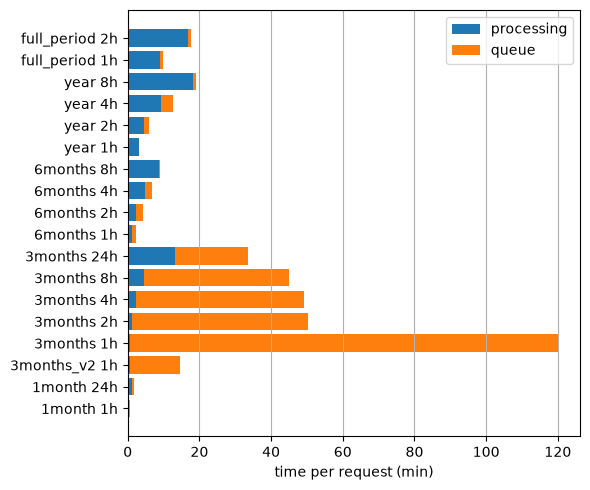

In [5]:
# median time per request: processing + queue
s = summary.dropna(subset=["processing_s"])
labels = s["chunk"].astype(str) + " " + s["hours_per_day"].astype(str) + "h"

plt.figure(figsize=(6, 5))
plt.barh(labels, s["processing_s"] / 60, label="processing")
plt.barh(labels, s["queue_s"] / 60, left=s["processing_s"] / 60, label="queue")
plt.gca().invert_yaxis()
plt.xlabel("time per request (min)")
plt.legend()
plt.grid(axis="x")
plt.tight_layout()
plt.show()

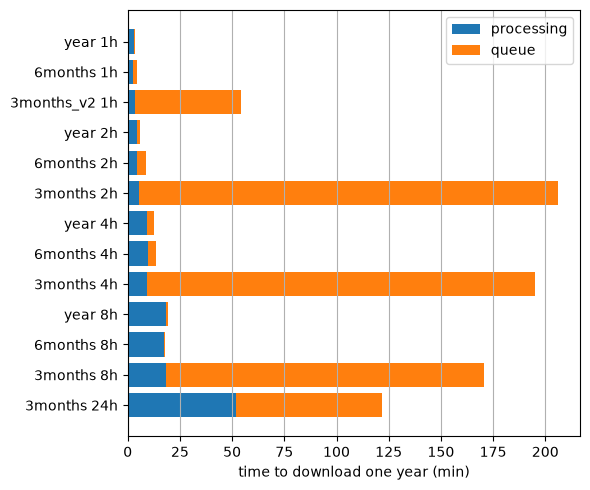

In [6]:
# total time to download one year (2003, 2004 for 3months_v2): sum over the requests of each test
n_expected = {"year": 1, "6months": 2, "3months": 4, "3months_v2": 4, "1month": 12}

one_year = requests[requests["chunk"].isin(list(n_expected)) & ~requests["refused"]]
total = (one_year.groupby(["chunk", "hours_per_day"])
         .agg(n=("file", "size"), queue_s=("queue_s", "sum"), processing_s=("processing_s", "sum"))
         .reset_index())
total = total[total["n"] == total["chunk"].map(n_expected)]   # only the tests that cover the whole year
total["chunk"] = pd.Categorical(total["chunk"], list(n_expected), ordered=True)
total = total.sort_values(["hours_per_day", "chunk"])   # grouped by hours
labels = total["chunk"].astype(str) + " " + total["hours_per_day"].astype(str) + "h"

plt.figure(figsize=(6, 5))
plt.barh(labels, total["processing_s"] / 60, label="processing")
plt.barh(labels, total["queue_s"] / 60, left=total["processing_s"] / 60, label="queue")
plt.gca().invert_yaxis()
plt.xlabel("time to download one year (min)")
plt.legend()
plt.grid(axis="x")
plt.tight_layout()
plt.show()